# 03. Modeling: validation, benchmark, tuning, selection, calibration

**Purpose.** Show how the model was chosen and how much to trust it. Notebook 01 explored the data and notebook 02 built the features; this notebook compares models, tunes the best ones, picks a final model by a rule fixed in advance, calibrates its confidence, and finally scores it once on the holdout.

**The result in one paragraph.** The final model blends a logistic regression with a LightGBM gradient-boosted tree model. In grouped cross-validation it is right on **95.4%** of invoice lines (a model that always answers the most common category gets 88.4%). On the 590 holdout rows it had never seen, it scores **97.1%**. Rows it is unsure about (about 8%) are sent to a person; the rest are 98.9% correct on the holdout.

**Terms used below.**

- **Cross-validation (CV):** split the training rows into 5 parts, train on 4 and test on the 5th, rotate, and average. Repeated with 3 random seeds, so every score is the mean over 15 test folds.
- **Grouped CV:** rows that are identical on every model input (with the date reduced to its month) always stay in the same part. Otherwise a test row's exact copy would sit in training and the score would be inflated (section 1 measures by how much).
- **Accuracy:** share of rows predicted correctly. **Macro F1:** the F1 score (balance of precision and recall) per class, averaged so that each of the five classes with 11 or more rows counts equally. It shows whether rare classes are found.
- **Out-of-time test:** train on months up to 2018-09, test on later months, the way the model would be used.
- **Log-odds:** the model's internal score. A positive contribution pushes toward the predicted category, a negative one away from it. The explanations in the dashboard use these exact numbers.
- **Calibration:** whether "90% confident" really means right 9 times out of 10.

**Ground rules.** Every transformer is fitted inside each training fold, so no statistic ever leaks from a test fold. The 590 holdout rows were never used for fitting, tuning, selection, calibration, or flag rules; their labels were read once, at the end (section 11). Every number comes from a report file written by the package (`python -m ledgerclf benchmark`, `tune`, `select`, `train`, `evaluate-holdout`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from _style import CLASS_COLORS, INK, INK_SECONDARY, MUTED, SEQUENTIAL, apply_style, report
from IPython.display import display

apply_style()
pd.set_option("display.precision", 4)
BLUE, ORANGE = CLASS_COLORS["Category_1"], CLASS_COLORS["Category_2"]

## 1. Validation strategy: why the folds are grouped

The ledger repeats itself: the same vendor, account, and description recur with the same label, often as exact copies that differ only by invoice number. A random split puts such copies of a test row into training. The chart compares four validation schemes for the same models, run on the training portion:

- **grouped CV**, the primary scheme;
- **random CV**, the leakage demonstration;
- **unseen-vendor CV**, where every vendor in a test fold is new;
- **out-of-time**, which trains up to September 2018 and tests on later months.

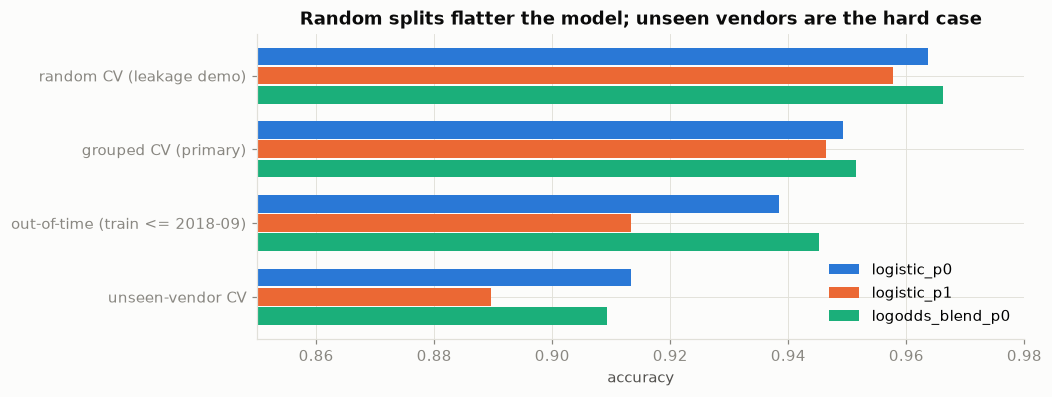

accuracy                               \
model                          logistic_p0 logistic_p1 logodds_blend_p0   
scheme                                                                    
random CV (leakage demo)            0.9636      0.9578           0.9663   
grouped CV (primary)                0.9493      0.9463           0.9514   
out-of-time (train <= 2018-09)      0.9384      0.9134           0.9451   
unseen-vendor CV                    0.9134      0.8896           0.9092   

                                macro_f1_5                               
model                          logistic_p0 logistic_p1 logodds_blend_p0  
scheme                                                                   
random CV (leakage demo)            0.8055      0.8037           0.8138  
grouped CV (primary)                0.6987      0.7200           0.6349  
out-of-time (train <= 2018-09)      0.6738      0.6602           0.8779  
unseen-vendor CV                    0.4154      0.3575           0.3980

In [2]:
schemes = report("benchmark/validation_schemes.csv")
pivot = schemes.pivot(index="scheme", columns="model", values="accuracy")
order = [
    "random CV (leakage demo)",
    "grouped CV (primary)",
    "out-of-time (train <= 2018-09)",
    "unseen-vendor CV",
]
pivot = pivot.loc[order]
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [BLUE, ORANGE, CLASS_COLORS["Category_3"]]
width = 0.26
for i, model in enumerate(pivot.columns):
    ax.barh(
        np.arange(len(order)) + (i - 1) * width,
        pivot[model],
        height=width - 0.02,
        color=colors[i],
        label=model,
    )
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlim(0.85, 0.98)
ax.set_xlabel("accuracy")
ax.set_title("Random splits flatter the model; unseen vendors are the hard case")
ax.legend(loc="lower right")
plt.show()
schemes.pivot(index="scheme", columns="model", values=["accuracy", "macro_f1_5"]).loc[order]

**Takeaway.**

- A random split overstates logistic accuracy by 1.4 points (0.964 against 0.949), which is the leakage grouping removes.
- Unseen vendors cost about 3.5 points more. This is the realistic risk for new suppliers, so those rows carry a critical flag.
- The out-of-time test sits between the two, which suggests mild drift across months.

## 2. Benchmark: every model family under the same folds

Five folds and three seeds, with the same grouped splits for every model. The macro F1 averages five classes. Category_5 is excluded because it has only two training rows, and its zero recall would add noise rather than information.

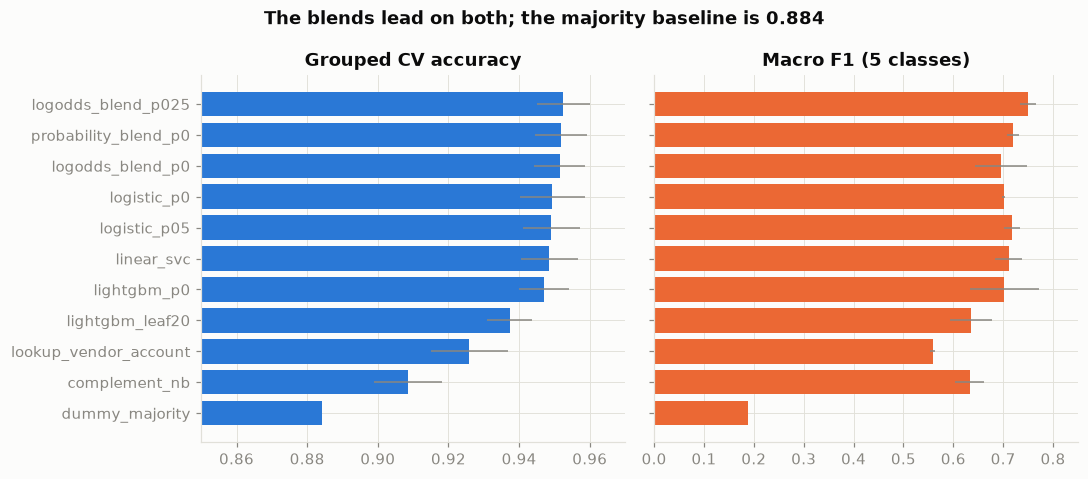

,model,accuracy_mean,accuracy_std,macro_f1_5_mean,recall_Category_2,recall_Category_3,recall_Category_4,recall_Category_6,fit_seconds
0,logodds_blend_p025,0.9525,7.5567e-03,0.7498,0.7799,0.9500,0.5714,0.3939,3.8974
1,probability_blend_p0,0.9518,7.3783e-03,0.7196,0.7512,0.9000,0.5476,0.2727,3.7882
2,logodds_blend_p0,0.9515,7.1710e-03,0.6957,0.7512,0.7833,0.5476,0.2727,3.8361
3,logistic_p0,0.9494,9.2185e-03,0.7009,0.7700,0.8667,0.5476,0.2121,0.1354
4,logistic_p05,0.9491,8.0624e-03,0.7179,0.8075,0.9167,0.5952,0.3939,0.1543
5,linear_svc,0.9485,8.0320e-03,0.7110,0.7934,0.9500,0.4762,0.3636,0.1125
6,lightgbm_p0,0.9470,7.0556e-03,0.7023,0.7201,0.7167,0.5714,0.2727,3.6615
7,lightgbm_leaf20,0.9373,6.4540e-03,0.6352,0.6772,0.5833,0.3810,0.2424,0.9683
8,lookup_vendor_account,0.9259,1.0932e-02,0.5583,0.6479,0.8500,0.0714,0.1818,0.0130
9,complement_nb,0.9086,9.5973e-03,0.6328,0.9243,0.9500,0.6190,0.4242,0.0404


In [3]:
board = report("benchmark/leaderboard.csv").sort_values("accuracy_mean")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
a1.barh(
    board["model"],
    board["accuracy_mean"],
    xerr=board["accuracy_std"],
    color=BLUE,
    error_kw={"ecolor": MUTED, "lw": 1},
)
a1.set_xlim(0.85, 0.97)
a1.set_title("Grouped CV accuracy")
a2.barh(
    board["model"],
    board["macro_f1_5_mean"],
    xerr=board["macro_f1_5_std"],
    color=ORANGE,
    error_kw={"ecolor": MUTED, "lw": 1},
)
a2.set_xlim(0, 0.85)
a2.set_title("Macro F1 (5 classes)")
fig.suptitle(
    "The blends lead on both; the majority baseline is 0.884", color=INK, fontweight="bold"
)
plt.tight_layout()
plt.show()
board.sort_values("accuracy_mean", ascending=False)[
    [
        "model",
        "accuracy_mean",
        "accuracy_std",
        "macro_f1_5_mean",
        "recall_Category_2",
        "recall_Category_3",
        "recall_Category_4",
        "recall_Category_6",
        "fit_seconds",
    ]
]

**Takeaway.**

- Every learned model beats the 0.884 majority baseline, and the vendor-account lookup table shows how far simple memorization goes (0.926).
- Logistic regression and LightGBM make different errors, so blending their log-odds beats both members.
- Complement naive Bayes has the best Category_2 recall but gives up too much Category_1 precision to be competitive.

## 3. Ablations: which inputs matter

Each row drops or adds one feature group from the logistic baseline and reruns the same folds.

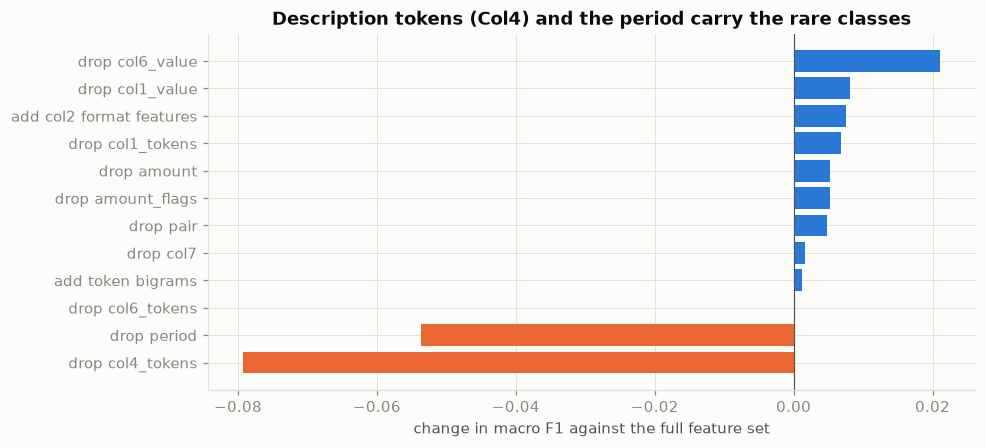

,variant,delta_accuracy,delta_macro_f1_5,recall_Category_4,recall_Category_6
3,drop col4_tokens,-1.7078e-02,-0.0793,0.2619,0.2121
10,drop period,-8.7950e-04,-0.0536,0.3810,0.1818
4,drop col6_tokens,-2.5128e-04,0.0003,0.5714,0.2121
12,add token bigrams,4.3877e-04,0.0012,0.5714,0.2121
7,drop col7,1.2555e-04,0.0016,0.5476,0.2121
6,drop pair,8.7873e-04,0.0048,0.5714,0.2121
9,drop amount_flags,-6.2952e-05,0.0052,0.5238,0.2424
8,drop amount,-1.1102e-16,0.0053,0.5476,0.2121
1,drop col1_tokens,-6.2952e-05,0.0069,0.5238,0.2727
11,add col2 format features,8.1631e-04,0.0076,0.5476,0.2424


In [4]:
ablation = report("benchmark/ablation.csv")
ablation = ablation[ablation["variant"] != "full feature set"].sort_values("delta_macro_f1_5")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(
    ablation["variant"],
    ablation["delta_macro_f1_5"],
    color=[ORANGE if v < 0 else BLUE for v in ablation["delta_macro_f1_5"]],
)
ax.axvline(0, color=INK_SECONDARY, lw=0.8)
ax.set_xlabel("change in macro F1 against the full feature set")
ax.set_title("Description tokens (Col4) and the period carry the rare classes")
plt.show()
ablation[
    ["variant", "delta_accuracy", "delta_macro_f1_5", "recall_Category_4", "recall_Category_6"]
]

**Takeaway.**

- Dropping the Col4 description tokens costs 1.7 accuracy points and 0.08 macro F1. Dropping the period costs 0.05 macro F1, mostly through Category_4.
- Dropping the Col6 whole value *raises* the logistic baseline's macro F1 by 0.021. That gain is about one more Category_6 row per seed (11 rows in total), and it does not carry over to the champion: in the champion configuration, dropping the same group lowers accuracy from 0.9539 to 0.9532 and macro F1 from 0.7475 to 0.7326. The feature set therefore stays unchanged.
- The vendor-account pair and Col7 are close to neutral on their own, because other groups carry the same information. The explanations use them by name.
- Col2 (the invoice number) is excluded from the model, and adding format features from it gains less than one fold's standard deviation.

## 4. Class weights: the accuracy and rare-class trade-off

Class weights are (n_max / n_c)^p. Power 0 means no weighting, and power 1 matches sklearn's `balanced`. Raising the power buys rare-class recall, but it also produces false rare alarms on majority rows in the out-of-time test.

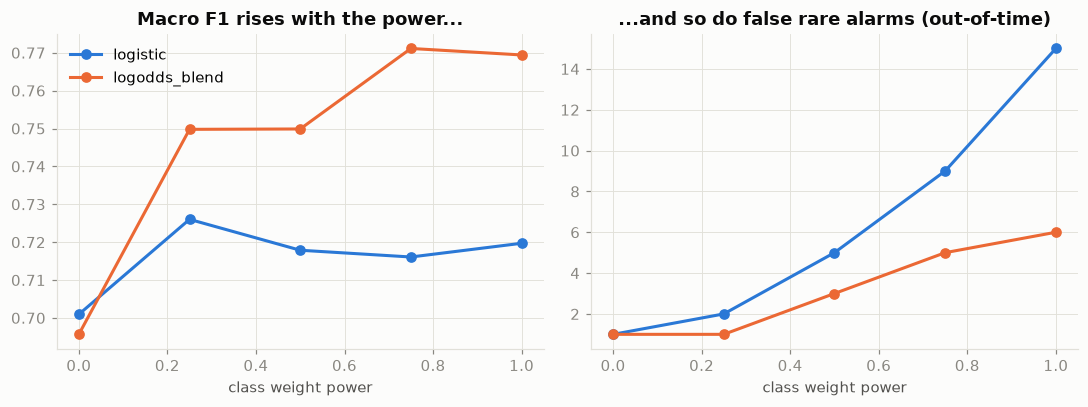

,model,power,cv_accuracy,cv_macro_f1_5,oot_accuracy,oot_macro_f1_5,oot_majority_rows_predicted_rare
0,logistic,0.00,0.9494,0.7009,0.9384,0.6738,1
1,logodds_blend,0.00,0.9515,0.6957,0.9451,0.8779,1
2,logistic,0.25,0.9500,0.7260,0.9346,0.6524,2
3,logodds_blend,0.25,0.9525,0.7498,0.9394,0.8731,1
4,logistic,0.50,0.9491,0.7179,0.9317,0.8185,5
5,logodds_blend,0.50,0.9520,0.7499,0.9413,0.8453,3
6,logistic,0.75,0.9474,0.7161,0.9259,0.7186,9
7,logodds_blend,0.75,0.9512,0.7711,0.9355,0.8220,5
8,logistic,1.00,0.9456,0.7197,0.9134,0.6602,15
9,logodds_blend,1.00,0.9498,0.7694,0.9317,0.8137,6


In [5]:
dial = report("benchmark/class_weight_dial.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
for model, color in [("logistic", BLUE), ("logodds_blend", ORANGE)]:
    part = dial[dial["model"] == model]
    a1.plot(part["power"], part["cv_macro_f1_5"], marker="o", ms=6, lw=2, color=color, label=model)
    a2.plot(
        part["power"],
        part["oot_majority_rows_predicted_rare"],
        marker="o",
        ms=6,
        lw=2,
        color=color,
        label=model,
    )
a1.set_title("Macro F1 rises with the power...")
a1.set_xlabel("class weight power")
a2.set_title("...and so do false rare alarms (out-of-time)")
a2.set_xlabel("class weight power")
a1.legend()
plt.tight_layout()
plt.show()
dial

**Takeaway.** A small power (0.25) captures most of the macro-F1 gain at almost no cost in false alarms. Tuning picks the power together with the other parameters.

## 5. Tuning: logged searches and nested CV

All three searches log every trial (`reports/tuning/*_trials.csv`) over grouped folds. Nested CV repeats the whole search inside each outer fold, which measures how optimistic it is to pick the best of many trials.

In [6]:
linear = report("tuning/linear_trials.csv")
tree = report("tuning/tree_trials.csv")
blend = report("tuning/blend_trials.csv")
print(f"Trials: linear {len(linear)}, tree {len(tree)}, blend {len(blend)}")
display(report("tuning/best_params.json"))
nested = report("tuning/nested_cv.json")
print(
    f"Nested CV accuracy {nested['outer_accuracy_mean']:.4f} +- {nested['outer_accuracy_std']:.4f}; "
    f"non-nested best {nested['non_nested_best_accuracy']:.4f}; optimism gap {nested['optimism_gap']:+.4f}"
)
pd.DataFrame(nested["outer_folds"])

Trials: linear 30, tree 40, blend 10


{'blend_weight_by_power': {'0.0': 0.7, '0.25': 0.7},
 'linear_by_power': {'0.0': {'C': 3.0}, '0.25': {'C': 3.0}},
 'ngram_range_by_power': {'0.0': [1, 2], '0.25': [1, 2]},
 'quick_mode': False,
 'tree': {'colsample_bytree': 0.8,
  'learning_rate': 0.1,
  'max_depth': -1,
  'min_child_samples': 1,
  'n_estimators': 800,
  'num_leaves': 31,
  'reg_lambda': 1.0,
  'subsample': 0.7}}

Nested CV accuracy 0.9548 +- 0.0050; non-nested best 0.9540; optimism gap -0.0008


,chosen_C,chosen_power,chosen_weight,inner_best_accuracy,outer_accuracy,outer_fold,outer_macro_f1_5,seconds
0,1.0,0.0,0.4,0.9477,0.9557,0,0.6382,33.7021
1,3.0,0.0,0.4,0.9534,0.9463,1,0.4605,25.5732
2,30.0,0.0,0.4,0.9498,0.9557,2,0.7894,26.2877
3,3.0,0.0,0.5,0.9491,0.9595,3,0.8262,26.3306
4,3.0,0.0,0.6,0.9517,0.9566,4,0.5031,26.5690


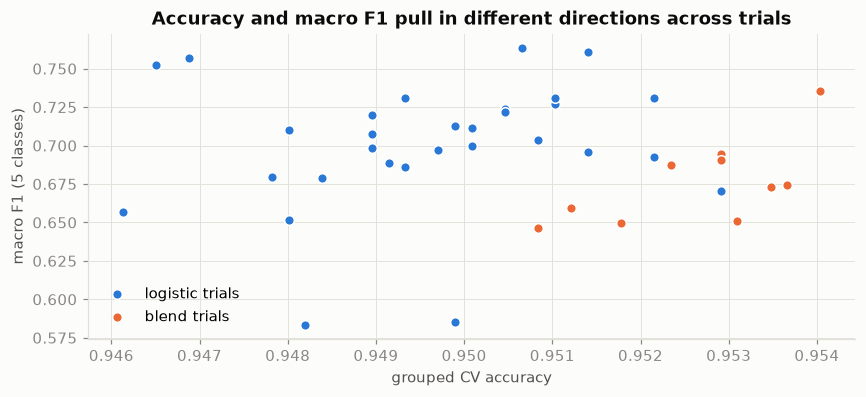

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(
    linear["mean_accuracy"],
    linear["mean_macro_f1_5"],
    s=40,
    color=BLUE,
    label="logistic trials",
    edgecolor="white",
    lw=1,
)
ax.scatter(
    blend["mean_accuracy"],
    blend["mean_macro_f1_5"],
    s=40,
    color=ORANGE,
    label="blend trials",
    edgecolor="white",
    lw=1,
)
ax.set_xlabel("grouped CV accuracy")
ax.set_ylabel("macro F1 (5 classes)")
ax.set_title("Accuracy and macro F1 pull in different directions across trials")
ax.legend()
plt.show()

**Takeaway.**

- Nested CV gives 0.9548, which matches the non-nested best (the gap is -0.0008), so selecting the best trial did not inflate the estimate.
- The trial cloud shows why a single accuracy number cannot pick the champion: the most accurate trials are not the ones with the best rare-class F1.

## 6. Champion selection by a rule fixed in advance

The rule was written down before tuning ran, so the final choice could not be steered by the results. It keeps candidates within 0.03 of the best macro F1 and within 0.015 of the best out-of-time accuracy (so the winner must handle rare classes and future months), then takes the best grouped-CV accuracy, preferring the simpler model on a near tie (within 0.002). The log-odds blend is also compared against a probability-averaging blend with identical members.

In [8]:
decision = report("selection/champion_decision.json")
for line in decision["trail"]:
    print("-", line)
print("Champion:", decision["champion"], "| Fallback:", decision["fallback"])
display(report("selection/champion_candidates.csv"))
report("selection/blend_comparison.csv")

- best macro_f1_5 = 0.7475; best out-of-time accuracy = 0.9480
- logistic_p0: cv 0.9513, macro_f1_5 0.6887, oot 0.9442 -> excluded
- logistic_p0.25: cv 0.9511, macro_f1_5 0.7389, oot 0.9336 -> eligible
- logodds_blend_p0: cv 0.9544, macro_f1_5 0.7159, oot 0.9480 -> excluded
- logodds_blend_p0.25: cv 0.9539, macro_f1_5 0.7475, oot 0.9403 -> eligible
- logodds_blend_p0.25 leads on CV accuracy by at least 0.002 (or is the only eligible candidate): chosen
Champion: logodds_blend_p0.25 | Fallback: logistic_p0


,name,family,power,cv_accuracy,cv_accuracy_std,macro_f1_5,oot_accuracy,oot_macro_f1_5,oot_rare_alarms
0,logistic_p0,logistic,0.00,0.9513,0.0082,0.6887,0.9442,0.6784,1
1,logistic_p0.25,logistic,0.25,0.9511,0.0077,0.7389,0.9336,0.8519,2
2,logodds_blend_p0,logodds_blend,0.00,0.9544,0.0064,0.7159,0.9480,0.8799,1
3,logodds_blend_p0.25,logodds_blend,0.25,0.9539,0.0068,0.7475,0.9403,0.8743,1


,model,power,cv_accuracy,cv_accuracy_std,macro_f1_5,accuracy_gap_vs_probability_blend
0,logodds_blend,0.25,0.9539,0.0068,0.7475,0.0008
1,probability_blend,0.25,0.9531,0.0069,0.7395,0.0000


**Takeaway.**

- The unweighted blend has the highest raw CV accuracy, but it fails the macro-F1 guardrail. The rule picks `logodds_blend_p0.25`: CV 0.9539, macro F1 0.747, out-of-time 0.940.
- Blending in log-odds space beats probability averaging by 0.0008. It also keeps every contribution exactly additive, which the explanations depend on.
- The fallback (an unweighted logistic regression) is what runs when LightGBM cannot load.

## 7. Out-of-fold errors: where the champion is wrong

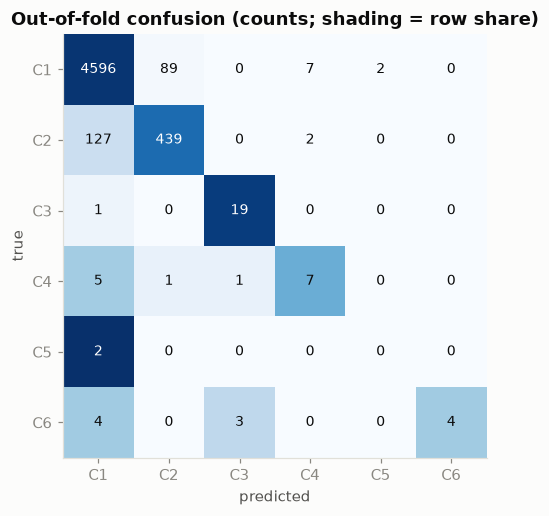

,class,precision,recall,f1,support
0,Category_1,0.9706,0.9791,0.9749,4694
1,Category_2,0.8299,0.7729,0.8004,568
2,Category_3,0.8261,0.9500,0.8837,20
3,Category_4,0.4375,0.5000,0.4667,14
4,Category_5,0.0000,0.0000,0.0000,2
5,Category_6,1.0000,0.3636,0.5333,11


In [9]:
confusion = report("selection/oof_confusion_matrix.csv").set_index("true_label")
fig, ax = plt.subplots(figsize=(6.4, 5))
shares = confusion.div(confusion.sum(axis=1), axis=0)
ax.imshow(shares, cmap=SEQUENTIAL, vmin=0, vmax=1)
for i in range(len(confusion)):
    for j in range(len(confusion.columns)):
        value = confusion.iat[i, j]
        ax.text(
            j,
            i,
            value,
            ha="center",
            va="center",
            fontsize=9,
            color="white" if shares.iat[i, j] > 0.6 else INK,
        )
ax.set_xticks(range(6), [c.replace("Category_", "C") for c in confusion.columns])
ax.set_yticks(range(6), [c.replace("Category_", "C") for c in confusion.index])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.grid(False)
ax.set_title("Out-of-fold confusion (counts; shading = row share)")
plt.show()
report("selection/oof_classification_report.csv")

**Takeaway.**

- Most errors are Category_1 and Category_2 swaps: 89 and 127 rows. Their vendors and accounts overlap.
- Category_3 is recognized well (recall 0.95), while Category_4 and Category_6 are found half the time or less.
- Category_5 has two training rows and is never predicted correctly out of fold. The model card states this limit.

## 8. Calibration and the review threshold

The blend's raw logits are over-confident. A single temperature, fitted on out-of-fold logits, divides every logit by the same number, so calibration changes neither the predicted class nor the additivity of the explanations.

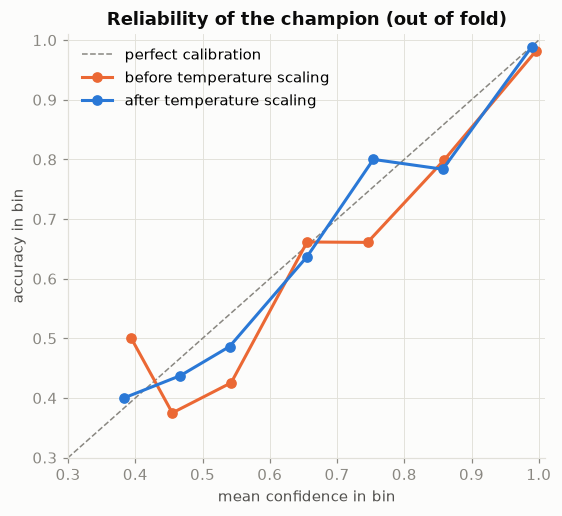

,brier_after,brier_before,ece_after,ece_before,log_loss_after,log_loss_before,temperature
logistic_p0,0.0713,0.0715,0.0056,0.0085,0.1251,0.1256,1.0759
logodds_blend_p0.25,0.0667,0.0690,0.0066,0.0189,0.1189,0.1297,1.3924


In [10]:
reliability = report("selection/calibration_reliability.csv")
champion = decision["champion"]
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="perfect calibration")
for stage, color in [("before", ORANGE), ("after", BLUE)]:
    part = reliability[
        (reliability["model"] == champion)
        & (reliability["stage"] == stage)
        & (reliability["rows"] > 0)
    ]
    ax.plot(
        part["mean_confidence"],
        part["accuracy"],
        marker="o",
        ms=6,
        lw=2,
        color=color,
        label=f"{stage} temperature scaling",
    )
ax.set_xlabel("mean confidence in bin")
ax.set_ylabel("accuracy in bin")
ax.set_xlim(0.3, 1.01)
ax.set_ylim(0.3, 1.01)
ax.set_title("Reliability of the champion (out of fold)")
ax.legend(loc="upper left")
plt.show()
summary = report("selection/calibration_summary.json")
pd.DataFrame({k: v for k, v in summary.items() if isinstance(v, dict)}).T

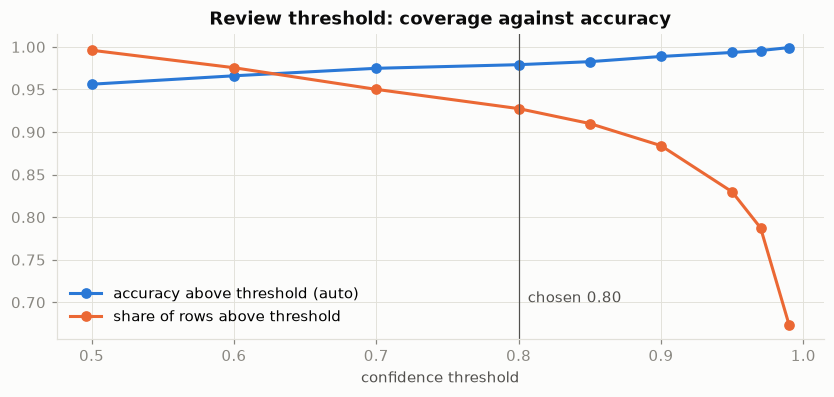

,threshold,coverage,accuracy_kept,accuracy_flagged,rows_flagged,chosen
0,0.50,0.9960,0.9561,0.4286,21,False
1,0.60,0.9755,0.9660,0.4769,130,False
2,0.70,0.9501,0.9748,0.5585,265,False
3,0.80,0.9275,0.9791,0.6338,385,True
4,0.85,0.9100,0.9826,0.6653,478,False
5,0.90,0.8840,0.9887,0.6899,616,False
6,0.95,0.8297,0.9934,0.7622,904,False
7,0.97,0.7873,0.9957,0.7998,1129,False
8,0.99,0.6736,0.9992,0.8609,1733,False


In [11]:
thresholds = report("selection/threshold_table.csv")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(
    thresholds["threshold"],
    thresholds["accuracy_kept"],
    marker="o",
    ms=6,
    lw=2,
    color=BLUE,
    label="accuracy above threshold (auto)",
)
ax.plot(
    thresholds["threshold"],
    thresholds["coverage"],
    marker="o",
    ms=6,
    lw=2,
    color=ORANGE,
    label="share of rows above threshold",
)
chosen = thresholds[thresholds["chosen"]].iloc[0]
ax.axvline(chosen["threshold"], color=INK_SECONDARY, lw=0.8)
ax.annotate(
    f"chosen {chosen['threshold']:.2f}",
    (chosen["threshold"], 0.7),
    xytext=(6, 0),
    textcoords="offset points",
    color=INK_SECONDARY,
)
ax.set_xlabel("confidence threshold")
ax.set_title("Review threshold: coverage against accuracy")
ax.legend(loc="lower left")
plt.show()
thresholds

**Takeaway.**

- Temperature 1.39 cuts the expected calibration error from 0.019 to 0.007.
- The review threshold is the lowest confidence level at which the automatically decided rows reach 97.5% accuracy; that is 0.8. Then 92.7% of rows are decided automatically at 97.9% accuracy. The remaining 7.3% go to review, and that group's accuracy is only 63%.

## 9. Flags: what sends a row to review

Each flag's severity comes from its out-of-fold accuracy: a flag whose rows are at least 5 points less accurate than average (with 10 or more rows of evidence) becomes critical. The statistics behind the flags (known vendors, accounts, ranges) are rebuilt from each fold's training rows only. A critical flag requires review. Flags never withhold a prediction.

In [12]:
flags = report("selection/accuracy_by_flag.csv")
display(flags)
report("selection/high_confidence_errors.csv").head(10)

,flag,rows,accuracy,severity
0,UNSEEN_VENDOR,154,0.8961,critical
1,UNSEEN_ACCOUNT,112,0.8929,critical
2,UNSEEN_VENDOR_ACCOUNT_PAIR,377,0.9363,warning
3,UNSEEN_DOC_TYPE,0,NaN,warning
4,ALL_TOKENS_UNSEEN,0,NaN,critical
5,TEXT_MISSING,0,NaN,critical
6,AMOUNT_IMPUTED,0,NaN,critical
7,AMOUNT_OUT_OF_RANGE,0,NaN,warning
8,DATE_IMPUTED,0,NaN,critical
9,DATE_OUT_OF_RANGE,0,NaN,warning


,row_id,Col1,Col4,Col6,Col5,amount,true_label,predicted_label,confidence
0,1623,Word90 Word91 Word92 Word7,Word202 Word592,Word567 Word582 Word41 Word319,2018-07,14668.5,Category_2,Category_1,0.9985
1,5036,Word42 Word43 Word5,Word9 Word2040 Word804 Word805 Word1327,Word565 Word566,2018-01,4480.0,Category_2,Category_1,0.9927
2,4628,Word80 Word3 Word4,Word1644 Word954 Word1032 Word856,Word563 Word580 Word755,2018-01,5485.0,Category_2,Category_1,0.9902
3,5620,Word193 Word311 Word214 Word4 Word7,Word123 Word190,Word563 Word564 Word9 Word26,2018-09,680.0,Category_2,Category_1,0.9873
4,541,Word218 Word22 Word4 Word5,Word800 Word757 Word1072,Word567 Word582 Word366 Word562,2018-08,12520.0,Category_2,Category_1,0.9873
5,1519,Word16 Word17 Word18 Word7,Word800 Word1450,Word563 Word580 Word581 Word232,2018-05,180.0,Category_2,Category_1,0.9855
6,2439,Word96 Word3 Word4 Word5,Word1587 Word797 Word190,Word560 Word561 Word366 Word562,2018-04,12620.0,Category_2,Category_1,0.9848
7,263,Word110 Word22 Word4 Word5,Word797 Word190,Word52 Word330 Word566,2018-06,1109.5,Category_2,Category_1,0.9844
8,1567,Word96 Word3 Word4 Word5,Word1018 Word190,Word563 Word564 Word9 Word26,2018-10,3940.0,Category_2,Category_1,0.9839
9,2807,Word85 Word86 Word87 Word5 Word88 Word16 Word1...,Word994 Word674,Word563 Word580 Word581 Word232,2018-02,630.0,Category_1,Category_2,0.9797


**Takeaway.**

- Rows with no flag reach 98.2% accuracy. Rows with an unseen vendor or account fall to about 89%, and low-confidence rows to 63%.
- High-confidence errors (confidence 0.9 or more, yet wrong) are listed for label review. Some are likely label inconsistencies in the source data.

## 10. One explanation, end to end

The dashboard's agent explains rows from the same exact payload shown here. The cell predicts the holdout **feature** file, which has no labels, and explains its first row. The payload's contributions add up to the logit margin between the predicted class and the runner-up.

In [13]:
from ledgerclf.service import PredictionService

service = PredictionService.load(auto_train=False)
features_file = service.settings.paths.holdout / "holdout_features.xlsx"
result = service.predict_file(features_file.read_bytes(), features_file.name)
payload = service.explain(result, 1)
print(payload["fallback_text"])
groups = pd.DataFrame(payload["contributions"]["by_group"])
total = groups["contribution"].sum() + payload["contributions"]["bias"]
print(
    f"\nSum of group contributions + bias = {total:.6f}; logit margin = {payload['prediction']['logit_margin']:.6f}"
)
groups

**Summary:** This invoice line most likely belongs to Category_1. The model is very confident (95%), mainly because most invoices (88%) belong to Category_1; this line's own details lean toward Category_2. It can be used without manual review.

**Model facts**
- Prediction: Category_1 at 95.1% (runner-up Category_2 at 4.5%), calibrated probability.
- Drivers (log-odds, Category_1 versus Category_2; positive supports Category_1): GL account (Col6) -0.98, vendor (Col1) +0.42, document flag (Col7) -0.39; class base rate +4.86.
- History: 4 of 4 past invoices with this vendor (Col1) were Category_1.
- History: 42 of 47 past invoices with this GL account (Col6) were Category_1.
- History: this vendor-account pair does not appear in the historical invoices.

**What to check:** No review required, but note: New combination: this vendor and GL account were never used together before.

Sum of group contributions + bias = 3.043772; logit margin = 3.043772


,group,label,contribution
0,Col6,GL account (Col6),-0.9784
1,Col1,vendor (Col1),0.4174
2,Col7,document flag (Col7),-0.3889
3,Col5,posting period (Col5),-0.2916
4,Col1+Col6,vendor-account pair,-0.2724
5,Col3,amount (Col3),-0.2283
6,Col4,line description (Col4),-0.0753


## 11. Holdout evaluation: the final check on unseen data

The 590 holdout rows were set aside before any analysis and scored exactly once, with the final models exactly as trained above. `reports/holdout/access_log.csv` records the time, code version, and model files of that single run.

In [14]:
evaluation = report("holdout/holdout_evaluation.json")
measures = [
    "accuracy",
    "macro_f1_5",
    "balanced_accuracy",
    "ece",
    "review_share",
    "accuracy_auto",
    "accuracy_reviewed",
]
table = pd.DataFrame(
    {name: {m: evaluation[name][m] for m in measures} for name in ("champion", "fallback_logistic")}
)
chosen = report("selection/threshold_table.csv").query("chosen").iloc[0]
calibration = report("selection/calibration_summary.json")[
    evaluation["cv_estimate_champion"]["name"]
]
cv = {
    "accuracy": evaluation["cv_estimate_champion"]["cv_accuracy"],
    "macro_f1_5": evaluation["cv_estimate_champion"]["macro_f1_5"],
    "ece": calibration["ece_after"],
    "review_share": 1 - chosen["coverage"],
    "accuracy_auto": chosen["accuracy_kept"],
    "accuracy_reviewed": chosen["accuracy_flagged"],
}
table["cross-validation (champion, out of fold)"] = pd.Series(cv)
display(table.round(4).fillna("-"))
display(report("holdout/access_log.csv"))

,champion,fallback_logistic,"cross-validation (champion, out of fold)"
accuracy,0.9712,0.9525,0.9539
macro_f1_5,0.7068,0.6880,0.7475
balanced_accuracy,0.7663,0.7537,-
ece,0.0114,0.0231,0.0066
review_share,0.0881,0.0881,0.0725
accuracy_auto,0.9888,0.9888,0.9791
accuracy_reviewed,0.7885,0.5769,0.6338


,utc,git_commit,reason,champion_sha256,fallback_sha256
0,2026-10-17T18:19:04+00:00,176cfa7,final evaluation,d0058cfe95f8504b1c286537393416f71b76adccf3561c...,061792d93154bf074eb8b44420dbe4eeffd1b4c9ee89c0...


In [15]:
holdout_confusion = report("holdout/holdout_confusion_matrix.csv").set_index("true_label")
holdout_confusion = holdout_confusion.loc[holdout_confusion.sum(axis=1) > 0]
display(holdout_confusion)
report("holdout/holdout_classification_report.csv")

,Category_1,Category_2,Category_3,Category_4,Category_5,Category_6
true_label,,,,,,
Category_1,516,4,0,0,0,1
Category_2,10,53,0,0,0,0
Category_3,0,0,3,0,0,0
Category_4,2,0,0,0,0,0
Category_6,0,0,0,0,0,1


,class,precision,recall,f1,support
0,Category_1,0.9773,0.9904,0.9838,521
1,Category_2,0.9298,0.8413,0.8833,63
2,Category_3,1.0000,1.0000,1.0000,3
3,Category_4,0.0000,0.0000,0.0000,2
4,Category_5,0.0000,0.0000,0.0000,0
5,Category_6,0.5000,1.0000,0.6667,1


In [16]:
report("holdout/holdout_accuracy_by_flag.csv")

,flag,rows,accuracy
0,LOW_CONFIDENCE,40,0.7750
1,UNSEEN_ACCOUNT,4,0.7500
2,UNSEEN_VENDOR,12,0.9167
3,UNSEEN_VENDOR_ACCOUNT_PAIR,34,0.9412


**Takeaway.**

- **Accuracy 97.1%** for the final model and 95.3% for the fallback. Both beat the 88.4% majority baseline by a wide margin.
- **Review routing works on new data.** 8.8% of holdout rows were sent to review. The rows decided automatically were 98.9% correct, and the reviewed rows only 78.9%, so the threshold sends exactly the risky rows to a person.
- **The holdout score is above the cross-validation estimate**, by about 2 standard errors on 590 rows. Two effects explain most of it. First, the final model learned from all 5,309 training rows, while each CV model saw about 4,250. Second, the holdout has slightly fewer unfamiliar rows (2.0% new vendors against 2.9% in CV). Training and holdout share no group and no identical row. **The honest expectation for new data is the CV figure, about 95%.**
- **Rare classes:** Category_3 was found 3 of 3 times and Category_6 1 of 1. Both Category_4 rows were predicted as Category_1. With 1 to 3 holdout rows per rare class, the holdout macro F1 (0.71) is too noisy to compare closely with CV (0.75).
- **Calibration holds:** expected calibration error 0.011 on the holdout.